In [1]:
from tensorflow.keras.layers import Input, Conv2D,ReLU
from tensorflow.keras.layers import MaxPool2D, BatchNormalization, Dropout, AveragePooling2D, GlobalAveragePooling2D
from tensorflow.keras import Model
from tensorflow.keras.layers import ReLU, concatenate
import tensorflow.keras.backend as K
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cv2
import warnings
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from tensorflow.keras.utils import to_categorical
from sklearn import metrics
from sklearn.metrics import confusion_matrix
# Suppress warnings
warnings.filterwarnings("ignore")

In [2]:
# Paths to dataset
path_train = "./train"
path_test = "./test"

In [3]:
# Train dataset processing
dataset_path_train = os.listdir(path_train)
disease_items_train = []
for item in dataset_path_train:
    all_disease = os.listdir(os.path.join(path_train, item))
    for disease in all_disease:
        disease_items_train.append((item, os.path.join(path_train, item, disease)))

train_disease_df = pd.DataFrame(data=disease_items_train, columns=['Train_Disease_Type', 'Train_Disease_Image'])

In [4]:
# Test dataset processing
dataset_path_validation = os.listdir(path_test)
disease_items_test = []
for item in dataset_path_validation:
    all_disease = os.listdir(os.path.join(path_test, item))
    for disease in all_disease:
        disease_items_test.append((item, os.path.join(path_test, item, disease)))

test_disease_df = pd.DataFrame(data=disease_items_test, columns=['Test_Disease_Type', 'Test_Disease_Image'])

In [5]:
# Image dimensions
img_width = 224
img_height = 224

# Train images and labels
train_images = []
train_labels = []
for i in dataset_path_train:
    data_path = os.path.join(path_train, i)
    file_names = os.listdir(data_path)
    for f in file_names:
        img = cv2.imread(os.path.join(data_path, f))
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
        img = cv2.resize(img, (img_width, img_height))
        train_images.append(img)
        train_labels.append(i)

train_labels = np.array(train_labels)

In [6]:
# Test images and labels
test_images = []
test_labels = []
for i in dataset_path_validation:
    data_path = os.path.join(path_test, i)
    file_names = os.listdir(data_path)
    for f in file_names:
        img = cv2.imread(os.path.join(data_path, f))
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
        img = cv2.resize(img, (img_width, img_height))
        test_images.append(img)
        test_labels.append(i)

test_labels = np.array(test_labels)

In [7]:
# Preprocess images
x_train = np.array(train_images).astype('float32') / 255.0
x_test = np.array(test_images).astype('float32') / 255.0

# Label encoding
y_train = train_disease_df['Train_Disease_Type'].values
y_test = test_disease_df['Test_Disease_Type'].values
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_train_one_hot = to_categorical(y_train)
y_test = le.fit_transform(y_test)
y_test_one_hot = to_categorical(y_test)

# Define DenseNet layers
filters = 32

In [8]:
def bn_rl_conv(x, filters, kernel=1, strides=1):
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = Conv2D(filters, kernel, strides=strides, padding='same')(x)
    return x

def dense_block(x, repetition):
    for _ in range(repetition):
        y = bn_rl_conv(x, 4*filters)
        y = bn_rl_conv(y, filters, 3)
        x = concatenate([y, x])
    return x

def transition_layer(x):
    x = bn_rl_conv(x, K.int_shape(x)[-1] // 2)
    x = AveragePooling2D(2, strides=2, padding='same')(x)
    return x

In [9]:
# DenseNet Model
input = Input(shape=(224, 224, 3))
x = Conv2D(64, 8, strides=2, padding='same')(input)
x = MaxPool2D(3, strides=2, padding='same')(x)
for repetition in [6, 12, 24, 16]:
    d = dense_block(x, repetition)
    x = transition_layer(d)
output = GlobalAveragePooling2D()(d)
feature_extractor = Model(inputs=input, outputs=output)

In [10]:
# LightGBM Classifier
import lightgbm as lgbm
LightGBM_Classifier = lgbm.LGBMClassifier()
x_feature_LGBMClassifier_train = feature_extractor.predict(x_train)
LightGBM_Classifier.fit(x_feature_LGBMClassifier_train, y_train)
x_feature_LGBMClassifier_test = feature_extractor.predict(x_test)
predicted_LGBMClassifier = LightGBM_Classifier.predict(x_feature_LGBMClassifier_test)
predicted_LGBMClassifier = le.inverse_transform(predicted_LGBMClassifier)

28/28 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.035408 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 261111
[LightGBM] [Info] Number of data points in the train set: 885, number of used features: 1024
[LightGBM] [Info] Start training from score -2.180417
[LightGBM] [Info] Start training from score -2.058200
[LightGBM] [Info] Start training from score -2.180417
[LightGBM] [Info] Start training from score -2.058200
[LightGBM] [Info] Start training from score -2.180417
[LightGBM] [Info] Start training from score -2.481523
[LightGBM] [Info] Start training from score -1.822743
[LightGBM] [Info] Start training from score -1.829761
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [W

In [11]:
# Metrics
print("Accuracy:", metrics.accuracy_score(test_labels, predicted_LGBMClassifier))
print("Precision:", metrics.precision_score(test_labels, predicted_LGBMClassifier, average='macro'))
print("Recall:", metrics.recall_score(test_labels, predicted_LGBMClassifier, average='macro'))
print("F1 Score:", metrics.f1_score(test_labels, predicted_LGBMClassifier, average='macro'))

Accuracy: 0.9988700564971752
Precision: 0.9987623762376238
Recall: 0.99875
F1 Score: 0.9987499687492187


./test/gray light/IMG_20220503_135527.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step
The prediction for this image is: gray light


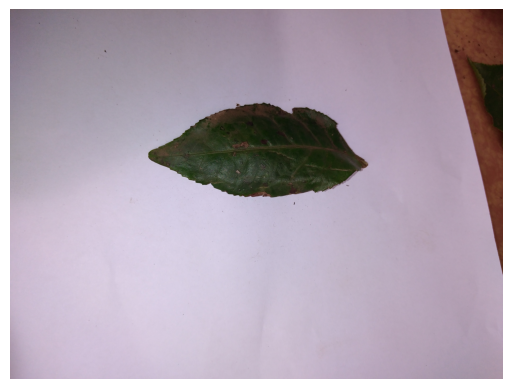

In [19]:
# Load a single image (replace with the path to your image)
img_path = './test/gray light/IMG_20220503_135527.jpg'
print(img_path)
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_resized = cv2.resize(img, (img_width, img_height))
img_resized = img_resized.astype('float32') / 255.0
img_resized = np.expand_dims(img_resized, axis=0)
img_feature = feature_extractor.predict(img_resized)
predicted_LGBMClassifier = LightGBM_Classifier.predict(img_feature)
predicted_LGBMClassifier = le.inverse_transform(predicted_LGBMClassifier)
print("The prediction for this image is:", predicted_LGBMClassifier[0])
plt.imshow(img)
plt.axis('off')  # Hide axis labels
plt.show()
